# Guardrail effects in the coffee-shop simulations

This notebook answers two questions for the paper:

1. **Do guardrails have an effect** on how the multi-agent system behaves?
2. **If so, what kind of effect**, and does it differ between **soft** (LLM-judge) and **hard** (predicate) guardrails?

It starts with **simulation success**: did the customer actually get what the scenario asked for? Later sections will add further outcomes.

### Design

Two setup families, each in four enforcement variants. Within a family, all four variants have the same agents, prompts, guidelines and rules. They differ only in how the rules are enforced:

| Variant | Setups | Enforcement |
|---|---|---|
| `flag` | `baseline_flag`, `strict_flow_flag` | All rules are evaluated but never block. This is the **reference** condition. |
| `normal` | `baseline`, `strict_flow` | The class reference: a mix of hard and soft rules that block. |
| `soft` | `baseline_soft`, `strict_flow_soft` | All rules are LLM judges that block. |
| `hard` | `baseline_hard`, `strict_flow_hard` | All rules are predicates that block. |

`flag` keeps every rule evaluating, so it is the right control: it shows what the agents do when nothing is enforced. Every other variant is compared against the `flag` variant of the **same family**.

### Contents

0. Configuration
1. Data
2. Success definition
3. Reference: success rate in the `flag` setups
4. Effect of enforcement per scenario
5. Effect of enforcement pooled over scenarios
6. Soft vs hard
7. Run-to-run consistency
8. Next analyses

## 0. Configuration

`RUN_DIRS` lists the run folders copied from the simulation machine. Each holds an `mlflow.db` and an `experiment_runs/<run_id>/ledger.json`. To include a new run, add its folder here and re-run the notebook.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ANALYSIS_DIR = Path.cwd()
sys.path.insert(0, str(ANALYSIS_DIR))

import rate_stats as rs  # noqa: E402
from run_data import load_runs  # noqa: E402

EXPERIMENT_RUNS = ANALYSIS_DIR.parent.parent / "experiment_runs"
RUN_DIRS = {
    "mini": EXPERIMENT_RUNS / "mini",
    "more": EXPERIMENT_RUNS / "more",
}

FAMILIES = ["baseline", "strict_flow"]
ENFORCEMENTS = ["flag", "normal", "soft", "hard"]
TREATMENTS = ["normal", "soft", "hard"]
SCENARIOS = {1: "S1 latte + croissant", 3: "S3 complaint", 4: "S4 recommendation"}

# Reference gray for `flag`, then the first three categorical slots.
COLORS = {"flag": "#8a8984", "normal": "#2a78d6", "soft": "#eb6834", "hard": "#1baf7a"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": MUTED,
        "axes.titlecolor": INK,
        "axes.titlesize": 10,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "legend.frameon": False,
        "font.size": 9,
    }
)
pd.options.display.float_format = "{:.3f}".format

## 1. Data

### 1.1 Runs

Only runs made with the same code, model and machine seed should be pooled. Check that the `commit`, `model` and `machine_seed` columns agree.

In [2]:
runs, conversations, tool_calls = load_runs(RUN_DIRS)
runs

,run,run_id,commit,model,machine_seed,setups,scenarios,per_cell,cells_done,cells
0,mini,20261028-155640,aca2f36,ollama:ministral-3:14b,100,8,"[1, 3, 4]",9,24,24
1,more,20261029-185412,aca2f36,ollama:ministral-3:14b,100,8,"[1, 3, 4]",16,24,24


In [3]:
assert (
    runs.commit.nunique() == 1
    and runs.model.nunique() == 1
    and runs.machine_seed.nunique() == 1
), "runs differ in code, model or machine seed; compare them instead of pooling"
assert (runs.cells_done == runs.cells).all(), "a run has unfinished cells"

### 1.2 Conversations per cell

One conversation is one MLflow session, tagged with its setup and scenario. Every setup × scenario cell should hold `per_cell` conversations from each run.

In [4]:
cell_counts = conversations.pivot_table(
    index=["family", "enforcement"],
    columns=["scenario", "run"],
    values="thread_id",
    aggfunc="count",
).reindex(pd.MultiIndex.from_product([FAMILIES, ENFORCEMENTS]))
expected = runs.set_index("run").per_cell
assert all(
    (cell_counts.xs(r, axis=1, level="run") == n).all().all()
    for r, n in expected.items()
), "missing conversations"
cell_counts

scenario              1         3         4     
run                mini more mini more mini more
baseline    flag      9   16    9   16    9   16
            normal    9   16    9   16    9   16
            soft      9   16    9   16    9   16
            hard      9   16    9   16    9   16
strict_flow flag      9   16    9   16    9   16
            normal    9   16    9   16    9   16
            soft      9   16    9   16    9   16
            hard      9   16    9   16    9   16

### 1.3 Tool calls

The tool-call table has one row per tool call that actually **ran**. Calls a guardrail denied never reach the tool, so they are not in it. `result` is the tool's return value parsed as JSON, and `result_text` is the raw text, used for error strings.

In [5]:
tool_calls.groupby("tool").size().sort_values(ascending=False).to_frame("calls").T

tool,place_on_tray,transfer_to_agent,process_order,get_order,start_preparation,end_preparation,update_stock,check_inventory,estimate_prep_time,check_tray,clean_machine,offer_refund,offer_partial_refund,get_alternatives,calculate_total
calls,1183,1148,714,500,472,453,431,426,202,96,65,10,9,5,3


## 2. Success definition

Success is judged from what the system actually **did** (executed tool calls), not from what the agents said or from the customer's feedback score.

| Scenario | Customer goal | Success |
|---|---|---|
| S1 | a large latte and a croissant | Both a `latte` and a `croissant` were successfully placed on the tray during the conversation. |
| S3 | complaint about a cold cappuccino | At least one successful `place_on_tray` (e.g. a replacement), **or** at least one successful refund (`offer_refund` or `offer_partial_refund`). |
| S4 | a recommendation, then order it | At least one successful `place_on_tray`. |

What counts as successful:

- **`place_on_tray`:** the tool returned `status: success`. Unknown item names (for example `"large latte"`) and wrong order states return `status: error` and do not count.
- **Refund:** the tool returned a refund record (`refund_amount`). Calls for unknown order ids return `Error: ...` and do not count.
- **S1:** checked over the whole conversation. The latte and the croissant do not have to belong to the same order.

In [6]:
def _tray_ok(r):
    return isinstance(r, dict) and r.get("status") == "success"


def _refund_ok(r):
    return isinstance(r, dict) and "refund_amount" in r


calls = tool_calls.copy()
calls["item"] = calls.inputs.map(lambda i: str(i.get("item_name", "")).strip().lower())
tray_ok = calls[(calls.tool == "place_on_tray") & calls.result.map(_tray_ok)]
refund_ok = calls[
    calls.tool.isin(["offer_refund", "offer_partial_refund"])
    & calls.result.map(_refund_ok)
]

per_thread = pd.DataFrame(
    index=pd.Index(conversations.thread_id.unique(), name="thread_id")
)
per_thread["tray_any"] = per_thread.index.isin(tray_ok.thread_id)
per_thread["tray_latte"] = per_thread.index.isin(
    tray_ok[tray_ok.item == "latte"].thread_id
)
per_thread["tray_croissant"] = per_thread.index.isin(
    tray_ok[tray_ok.item == "croissant"].thread_id
)
per_thread["refund"] = per_thread.index.isin(refund_ok.thread_id)

conv = conversations.join(per_thread, on="thread_id")
SUCCESS_RULES = {
    1: lambda d: d.tray_latte & d.tray_croissant,
    3: lambda d: d.tray_any | d.refund,
    4: lambda d: d.tray_any,
}
conv["success"] = False
for scenario, rule in SUCCESS_RULES.items():
    mask = conv.scenario == scenario
    conv.loc[mask, "success"] = rule(conv[mask])
conv["success"] = conv.success.astype(bool)

**Sanity check.** How often each part of the definition holds, per scenario and variant, pooled over families and runs. For S3, the table shows whether success came from the tray, from a refund, or from both.

In [7]:
components = (
    conv.groupby(["scenario", "enforcement"])[
        ["tray_latte", "tray_croissant", "tray_any", "refund", "success"]
    ]
    .mean()
    .reindex(ENFORCEMENTS, level="enforcement")
)
components

tray_latte  tray_croissant  tray_any  refund  success
scenario enforcement                                                       
1        flag              0.760           0.860     0.960   0.000    0.660
         normal            0.820           0.880     0.920   0.020    0.780
         soft              0.680           0.820     0.900   0.020    0.600
         hard              0.740           0.880     0.900   0.040    0.720
3        flag              0.000           0.000     0.220   0.020    0.240
         normal            0.000           0.020     0.240   0.000    0.240
         soft              0.000           0.020     0.360   0.040    0.400
         hard              0.000           0.000     0.180   0.060    0.240
4        flag              0.400           0.360     0.800   0.020    0.800
         normal            0.080           0.300     0.720   0.000    0.720
         soft              0.060           0.360     0.800   0.000    0.800
         hard              0.040           0.360     0.840   0.000    0.840

In [8]:
s3 = conv[conv.scenario == 3]
pd.crosstab(
    [s3.family, s3.enforcement],
    pd.Categorical(
        np.select(
            [s3.tray_any & s3.refund, s3.tray_any, s3.refund],
            ["tray + refund", "tray only", "refund only"],
            "none",
        ),
        categories=["tray only", "refund only", "tray + refund", "none"],
    ),
    dropna=False,
).rename_axis(columns="S3 success via").reindex(
    pd.MultiIndex.from_product([FAMILIES, ENFORCEMENTS])
)

S3 success via      tray only  refund only  tray + refund  none
baseline    flag            6            1              0    18
            normal         10            0              0    15
            soft            5            1              0    19
            hard            5            2              0    18
strict_flow flag            5            0              0    20
            normal          2            0              0    23
            soft           13            1              0    11
            hard            4            1              0    20

Failed tray placements, by error message. These failures do not count as success, but they show why a conversation can look fine in the dialogue and still fail.

In [9]:
tray_errors = calls[
    (calls.tool == "place_on_tray") & ~calls.result.map(_tray_ok)
].copy()
tray_errors["message"] = tray_errors.result.map(
    lambda r: (r or {}).get("message", "unparseable")
)
tray_errors["kind"] = tray_errors.message.str.replace(
    r"^Unknown item: .*", "Unknown item", regex=True
).str.replace(r"order status is \w+", "order status is <status>", regex=True)
display(tray_errors.groupby("kind").size().to_frame("calls"))
tray_errors[tray_errors.kind == "Unknown item"].item.value_counts().head(10).to_frame(
    "calls (top 10 unknown names)"
)

,calls
kind,
Cannot place items — order status is <status>,32
Unknown item,557


,calls (top 10 unknown names)
item,
large latte,73
medium cappuccino,37
medium vanilla cappuccino,22
large cappuccino,18
large hot cappuccino,10
medium hot cappuccino,10
iced latte,10
vanilla cappuccino,10
blueberry muffin,9


### Helpers for the following sections

`rates()` counts successes per group and adds a Wilson 95% interval. `vs_reference()` compares one variant against another within the same family, cell by cell: risk difference, Newcombe 95% interval and Fisher's exact test. `pooled_vs_reference()` pools over strata (scenario × run, plus family where stated) with the Mantel-Haenszel risk difference and the CMH test.

In [10]:
def rates(df, by):
    g = df.groupby(by).success.agg(k="sum", n="count").reset_index()
    g["rate"] = g.k / g.n
    g[["lo", "hi"]] = g.apply(lambda r: pd.Series(rs.wilson(r.k, r.n)), axis=1)
    return g


def vs_reference(df, treatments, reference="flag", by=("family", "scenario")):
    by = list(by)
    counts = rates(df, by + ["enforcement"]).set_index(by + ["enforcement"])
    rows = []
    for key, group in counts.groupby(level=by):
        ref = group.xs(reference, level="enforcement").iloc[0]
        for t in treatments:
            trt = group.xs(t, level="enforcement").iloc[0]
            d, lo, hi = rs.newcombe_diff(trt.k, trt.n, ref.k, ref.n)
            rows.append(
                {
                    **dict(zip(by, key if isinstance(key, tuple) else (key,))),
                    "enforcement": t,
                    "ref_rate": ref.rate,
                    "rate": trt.rate,
                    "diff": d,
                    "lo": lo,
                    "hi": hi,
                    "p": rs.fisher_p(trt.k, trt.n, ref.k, ref.n),
                    "n_ref": int(ref.n),
                    "n": int(trt.n),
                }
            )
    out = pd.DataFrame(rows)
    out["p_holm"] = rs.holm(out.p)
    return out


def pooled_vs_reference(
    df, treatments, reference="flag", groups=("family",), strata=("scenario", "run")
):
    groups, strata = list(groups), list(strata)
    counts = df.groupby(groups + strata + ["enforcement"]).success.agg(
        k="sum", n="count"
    )
    rows = []
    for t in treatments:
        grouped = (
            counts.groupby(level=groups[0] if len(groups) == 1 else groups)
            if groups
            else [((), counts)]
        )
        for key, g in grouped:
            wide = g.unstack("enforcement")
            table = pd.DataFrame(
                {
                    "k1": wide["k"][t],
                    "n1": wide["n"][t],
                    "k0": wide["k"][reference],
                    "n0": wide["n"][reference],
                }
            ).fillna(0)
            mh = rs.mantel_haenszel_rd(table)
            label = dict(zip(groups, key if isinstance(key, tuple) else (key,)))
            rows.append(
                {
                    **label,
                    "enforcement": t,
                    "vs": reference,
                    "rate": table.k1.sum() / table.n1.sum(),
                    "ref_rate": table.k0.sum() / table.n0.sum(),
                    **mh,
                    "n": int(table.n1.sum()),
                    "n_ref": int(table.n0.sum()),
                }
            )
    out = pd.DataFrame(rows)
    out["p_holm"] = rs.holm(out.p_cmh)
    return out


def ci_axes(ax, title=None):
    ax.set_ylim(-0.02, 1.02)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    if title:
        ax.set_title(title, loc="left")

## 3. Reference: success rate in the `flag` setups

This shows what the agents achieve when every rule is evaluated but nothing is enforced, per family and scenario, pooled over runs. Intervals are Wilson 95%.

In [11]:
reference = conv[conv.enforcement == "flag"]
ref_rates = rates(reference, ["family", "scenario"])
ref_rates.pivot(
    index="scenario", columns="family", values=["k", "n", "rate", "lo", "hi"]
).rename(index=SCENARIOS)

k                    n                 rate  \
family               baseline strict_flow baseline strict_flow baseline   
scenario                                                                  
S1 latte + croissant   18.000      15.000   25.000      25.000    0.720   
S3 complaint            7.000       5.000   25.000      25.000    0.280   
S4 recommendation      23.000      17.000   25.000      25.000    0.920   

                                       lo                   hi              
family               strict_flow baseline strict_flow baseline strict_flow  
scenario                                                                    
S1 latte + croissant       0.600    0.524       0.407    0.857       0.766  
S3 complaint               0.200    0.143       0.089    0.476       0.391  
S4 recommendation          0.680    0.750       0.484    0.978       0.828

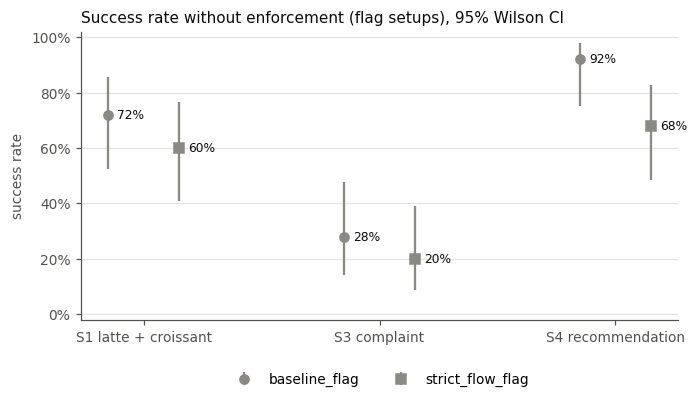

In [12]:
pooled_ref = rates(reference, ["scenario"]).assign(family="both families")
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(SCENARIOS))
offsets = {"baseline": -0.15, "strict_flow": 0.15}
markers = {"baseline": "o", "strict_flow": "s"}
for fam in FAMILIES:
    r = ref_rates[ref_rates.family == fam].set_index("scenario").loc[list(SCENARIOS)]
    ax.errorbar(
        x + offsets[fam],
        r.rate,
        yerr=[r.rate - r.lo, r.hi - r.rate],
        fmt=markers[fam],
        ms=6,
        color=COLORS["flag"],
        ecolor=COLORS["flag"],
        elinewidth=1.5,
        capsize=0,
        label=f"{fam}_flag",
    )
    for xi, v in zip(x + offsets[fam], r.rate):
        ax.annotate(
            f"{v:.0%}",
            (xi, v),
            xytext=(6, 0),
            textcoords="offset points",
            va="center",
            color=INK,
            fontsize=8,
        )
ax.set_xticks(x, SCENARIOS.values())
ci_axes(ax, "Success rate without enforcement (flag setups), 95% Wilson CI")
ax.set_ylabel("success rate")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncols=2)
plt.show()

The same reference rates per run, as a first look at how stable a cell is between runs (Section 7 covers all setups).

In [13]:
rates(reference, ["family", "scenario", "run"]).pivot(
    index=["family", "scenario"], columns="run", values="rate"
).rename(index=SCENARIOS, level="scenario")

run                               mini  more
family      scenario                        
baseline    S1 latte + croissant 0.778 0.688
            S3 complaint         0.444 0.188
            S4 recommendation    1.000 0.875
strict_flow S1 latte + croissant 0.778 0.500
            S3 complaint         0.222 0.188
            S4 recommendation    0.889 0.562

## 4. Effect of enforcement per scenario

Each enforcing variant (`normal`, `soft`, `hard`) is compared with the `flag` variant of the **same family and scenario**, pooled over runs.

- `diff` = rate − ref_rate, with a Newcombe 95% interval.
- `p` is Fisher's exact test (two-sided).
- `p_holm` corrects for the 18 comparisons in this table (Holm).

With about 25 conversations per cell, only large effects will be significant here. Section 5 pools the scenarios for more power.

In [14]:
all_rates = rates(conv, ["family", "scenario", "enforcement"])
all_rates.pivot(
    index=["family", "enforcement"], columns="scenario", values="rate"
).reindex(pd.MultiIndex.from_product([FAMILIES, ENFORCEMENTS])).rename(
    columns=SCENARIOS
)

scenario            S1 latte + croissant  S3 complaint  S4 recommendation
baseline    flag                   0.720         0.280              0.920
            normal                 0.880         0.400              0.800
            soft                   0.600         0.240              0.880
            hard                   0.720         0.280              0.840
strict_flow flag                   0.600         0.200              0.680
            normal                 0.680         0.080              0.640
            soft                   0.600         0.560              0.720
            hard                   0.720         0.200              0.840

In [15]:
per_scenario = vs_reference(conv, TREATMENTS)
per_scenario.assign(scenario=per_scenario.scenario.map(SCENARIOS)).style.format(
    {c: "{:.0%}" for c in ["ref_rate", "rate"]}
    | {c: "{:+.0%}" for c in ["diff", "lo", "hi"]}
    | {"p": "{:.3f}", "p_holm": "{:.3f}"}
).hide(axis="index")

family,scenario,enforcement,ref_rate,rate,diff,lo,hi,p,n_ref,n,p_holm
baseline,S1 latte + croissant,normal,72%,88%,+16%,-7%,+37%,0.289,25,25,1.000
baseline,S1 latte + croissant,soft,72%,60%,-12%,-36%,+14%,0.551,25,25,1.000
baseline,S1 latte + croissant,hard,72%,72%,+0%,-24%,+24%,1.000,25,25,1.000
baseline,S3 complaint,normal,28%,40%,+12%,-14%,+36%,0.551,25,25,1.000
baseline,S3 complaint,soft,28%,24%,-4%,-27%,+20%,1.000,25,25,1.000
baseline,S3 complaint,hard,28%,28%,+0%,-24%,+24%,1.000,25,25,1.000
baseline,S4 recommendation,normal,92%,80%,-12%,-32%,+8%,0.417,25,25,1.000
baseline,S4 recommendation,soft,92%,88%,-4%,-23%,+15%,1.000,25,25,1.000
baseline,S4 recommendation,hard,92%,84%,-8%,-28%,+11%,0.667,25,25,1.000
strict_flow,S1 latte + croissant,normal,60%,68%,+8%,-18%,+32%,0.769,25,25,1.000


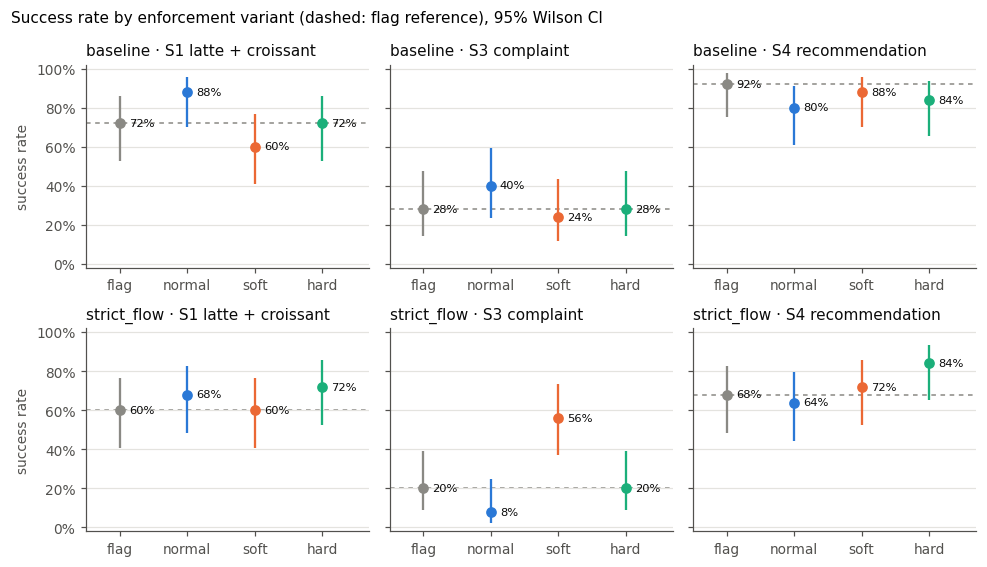

In [16]:
fig, axes = plt.subplots(len(FAMILIES), len(SCENARIOS), figsize=(9, 5.2), sharey=True)
for i, fam in enumerate(FAMILIES):
    for j, (scenario, label) in enumerate(SCENARIOS.items()):
        ax = axes[i, j]
        r = (
            all_rates[(all_rates.family == fam) & (all_rates.scenario == scenario)]
            .set_index("enforcement")
            .loc[ENFORCEMENTS]
        )
        ref_rate = r.loc["flag", "rate"]
        ax.axhline(ref_rate, color=COLORS["flag"], lw=1, ls=(0, (3, 3)), zorder=1)
        for k, e in enumerate(ENFORCEMENTS):
            ax.errorbar(
                k,
                r.loc[e, "rate"],
                yerr=[
                    [r.loc[e, "rate"] - r.loc[e, "lo"]],
                    [r.loc[e, "hi"] - r.loc[e, "rate"]],
                ],
                fmt="o",
                ms=6,
                color=COLORS[e],
                elinewidth=1.5,
                capsize=0,
                zorder=3,
            )
            ax.annotate(
                f"{r.loc[e, 'rate']:.0%}",
                (k, r.loc[e, "rate"]),
                xytext=(6, 0),
                textcoords="offset points",
                va="center",
                fontsize=7.5,
                color=INK,
            )
        ax.set_xticks(range(len(ENFORCEMENTS)), ENFORCEMENTS)
        ax.set_xlim(-0.5, len(ENFORCEMENTS) - 0.3)
        ci_axes(ax, f"{fam} · {label}")
    axes[i, 0].set_ylabel("success rate")
fig.suptitle(
    "Success rate by enforcement variant (dashed: flag reference), 95% Wilson CI",
    x=0.01,
    ha="left",
    fontsize=10,
)
fig.tight_layout()
plt.show()

## 5. Effect of enforcement pooled over scenarios

The scenarios differ a lot in base rate, so simply pooling their conversations would mix those base rates together. Instead, the comparison is **stratified**: each scenario × run stratum compares a variant with `flag`, and the Mantel-Haenszel risk difference combines the strata.

- `rd` is the stratified difference in success rate (variant − flag), in percentage points, with a 95% interval (Sato variance).
- `p_cmh` is the Cochran-Mantel-Haenszel test.
- `p_holm` corrects within each table.

### 5.1 Per family

In [17]:
FMT_POOLED = (
    {c: "{:.0%}" for c in ["ref_rate", "rate"]}
    | {c: "{:+.0%}" for c in ["rd", "lo", "hi"]}
    | {"p_cmh": "{:.3f}", "p_holm": "{:.3f}"}
)
pooled_family = pooled_vs_reference(conv, TREATMENTS, groups=["family"])
pooled_family.style.format(FMT_POOLED).hide(axis="index")

family,enforcement,vs,rate,ref_rate,rd,lo,hi,p_cmh,strata,n,n_ref,p_holm
baseline,normal,flag,69%,64%,+5%,-8%,+18%,0.426,6,75,75,1.000
strict_flow,normal,flag,47%,49%,-3%,-17%,+11%,0.709,6,75,75,1.000
baseline,soft,flag,57%,64%,-7%,-20%,+7%,0.328,6,75,75,1.000
strict_flow,soft,flag,63%,49%,+13%,-2%,+28%,0.085,6,75,75,0.507
baseline,hard,flag,61%,64%,-3%,-16%,+10%,0.693,6,75,75,1.000
strict_flow,hard,flag,59%,49%,+9%,-4%,+23%,0.187,6,75,75,0.937


### 5.2 Both families (Question 1)

Here the strata are family × scenario × run, so each family is still compared only with its own `flag` setup. This is the most direct answer to *do guardrails have an effect on success?*, separately for each enforcement type.

In [18]:
pooled_all = pooled_vs_reference(
    conv, TREATMENTS, groups=[], strata=["family", "scenario", "run"]
)
pooled_all.style.format(FMT_POOLED).hide(axis="index")

enforcement,vs,rate,ref_rate,rd,lo,hi,p_cmh,strata,n,n_ref,p_holm
normal,flag,58%,57%,+1%,-8%,+11%,0.786,12,150,150,1.000
soft,flag,60%,57%,+3%,-7%,+13%,0.518,12,150,150,1.000
hard,flag,60%,57%,+3%,-6%,+13%,0.496,12,150,150,1.000


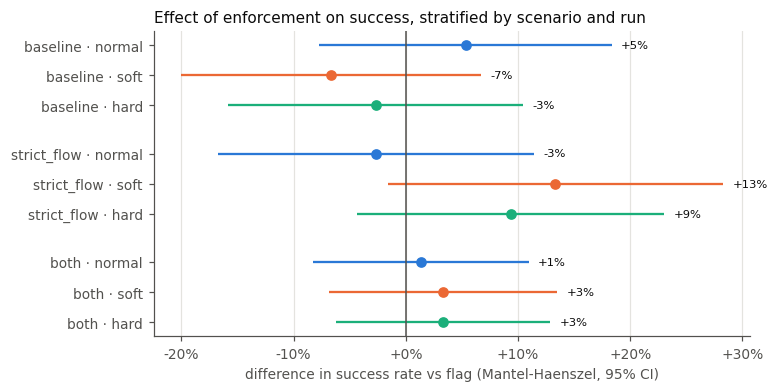

In [19]:
forest = pd.concat([pooled_family, pooled_all.assign(family="both")], ignore_index=True)
labels = ["baseline", "strict_flow", "both"]
fig, ax = plt.subplots(figsize=(7, 3.6))
y = 0
yticks, ylabels = [], []
for fam in labels:
    for e in TREATMENTS:
        r = forest[(forest.family == fam) & (forest.enforcement == e)].iloc[0]
        ax.errorbar(
            r.rd,
            y,
            xerr=[[r.rd - r.lo], [r.hi - r.rd]],
            fmt="o",
            ms=6,
            color=COLORS[e],
            elinewidth=1.5,
            capsize=0,
        )
        ax.annotate(
            f"{r.rd:+.0%}",
            (r.hi, y),
            xytext=(6, 0),
            textcoords="offset points",
            va="center",
            fontsize=7.5,
            color=INK,
        )
        yticks.append(y)
        ylabels.append(f"{fam} · {e}")
        y -= 1
    y -= 0.6
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(yticks, ylabels)
ax.grid(axis="x", color=GRID)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_xlabel("difference in success rate vs flag (Mantel-Haenszel, 95% CI)")
ax.set_title(
    "Effect of enforcement on success, stratified by scenario and run", loc="left"
)
plt.show()

## 6. Soft vs hard (Question 2)

Sections 4 and 5 compare each variant with `flag`. This section compares the enforcing variants **with each other**, using the same stratification (scenario × run, plus family for the pooled row): `hard` vs `soft`, and `normal` (mixed) vs each pure variant.

In [20]:
pairs = [("hard", "soft"), ("normal", "soft"), ("normal", "hard")]
head_to_head = pd.concat(
    [
        pooled_vs_reference(conv, [t], reference=ref, groups=["family"])
        for t, ref in pairs
    ]
    + [
        pooled_vs_reference(
            conv, [t], reference=ref, groups=[], strata=["family", "scenario", "run"]
        ).assign(family="both")
        for t, ref in pairs
    ],
    ignore_index=True,
)
head_to_head["p_holm"] = rs.holm(head_to_head.p_cmh)
head_to_head[
    [
        "family",
        "enforcement",
        "vs",
        "rate",
        "ref_rate",
        "rd",
        "lo",
        "hi",
        "p_cmh",
        "p_holm",
        "n",
        "n_ref",
    ]
].style.format(FMT_POOLED).hide(axis="index")

family,enforcement,vs,rate,ref_rate,rd,lo,hi,p_cmh,p_holm,n,n_ref
baseline,hard,soft,61%,57%,+4%,-10%,+18%,0.564,1.000,75,75
strict_flow,hard,soft,59%,63%,-4%,-19%,+11%,0.596,1.000,75,75
baseline,normal,soft,69%,57%,+12%,-2%,+26%,0.089,0.660,75,75
strict_flow,normal,soft,47%,63%,-16%,-31%,-1%,0.038,0.343,75,75
baseline,normal,hard,69%,61%,+8%,-5%,+21%,0.244,1.000,75,75
strict_flow,normal,hard,47%,59%,-12%,-26%,+2%,0.082,0.660,75,75
both,hard,soft,60%,60%,+0%,-10%,+10%,1.000,1.000,150,150
both,normal,soft,58%,60%,-2%,-13%,+9%,0.702,1.000,150,150
both,normal,hard,58%,60%,-2%,-12%,+8%,0.681,1.000,150,150


Per scenario, `hard` vs `soft` within each family (Newcombe interval, Fisher test, Holm over the 6 comparisons):

In [21]:
hard_vs_soft = vs_reference(conv, ["hard"], reference="soft")
hard_vs_soft.assign(scenario=hard_vs_soft.scenario.map(SCENARIOS)).rename(
    columns={"ref_rate": "soft_rate", "rate": "hard_rate"}
).style.format(
    {c: "{:.0%}" for c in ["soft_rate", "hard_rate"]}
    | {c: "{:+.0%}" for c in ["diff", "lo", "hi"]}
    | {"p": "{:.3f}", "p_holm": "{:.3f}"}
).hide(axis="index")

family,scenario,enforcement,soft_rate,hard_rate,diff,lo,hi,p,n_ref,n,p_holm
baseline,S1 latte + croissant,hard,60%,72%,+12%,-14%,+36%,0.551,25,25,1.000
baseline,S3 complaint,hard,24%,28%,+4%,-20%,+27%,1.000,25,25,1.000
baseline,S4 recommendation,hard,88%,84%,-4%,-24%,+16%,1.000,25,25,1.000
strict_flow,S1 latte + croissant,hard,60%,72%,+12%,-14%,+36%,0.551,25,25,1.000
strict_flow,S3 complaint,hard,56%,20%,-36%,-57%,-9%,0.019,25,25,0.112
strict_flow,S4 recommendation,hard,72%,84%,+12%,-11%,+34%,0.496,25,25,1.000


## 7. Run-to-run consistency

The runs use the same code, model and machine seed, so any difference between them is noise from the LLMs. If a cell's rate moves this much between runs, a difference of that size between setups is not meaningful. The table shows the rate per run and the difference (`more − mini`) with a Newcombe interval.

In [22]:
run_names = list(RUN_DIRS)
if len(run_names) >= 2:
    a, b = run_names[:2]
    per_run = rates(conv, ["family", "enforcement", "scenario", "run"]).pivot(
        index=["family", "enforcement", "scenario"], columns="run", values=["k", "n"]
    )
    consistency = pd.DataFrame(
        {
            a: per_run["k"][a] / per_run["n"][a],
            b: per_run["k"][b] / per_run["n"][b],
        }
    )
    diffs = [
        rs.newcombe_diff(
            per_run["k"][b][i],
            per_run["n"][b][i],
            per_run["k"][a][i],
            per_run["n"][a][i],
        )
        for i in per_run.index
    ]
    consistency[["diff", "lo", "hi"]] = diffs
    consistency = consistency.reindex(
        pd.MultiIndex.from_product([FAMILIES, ENFORCEMENTS, list(SCENARIOS)])
    )
    print(
        f"median |{b} - {a}|: {consistency['diff'].abs().median():.0%}, max: {consistency['diff'].abs().max():.0%}"
    )
    display(
        consistency.style.format("{:+.0%}", subset=["diff", "lo", "hi"]).format(
            "{:.0%}", subset=[a, b]
        )
    )

median |more - mini|: 23%, max: 38%


## 8. Next analyses

The per-conversation table `conv` (one row per conversation, with `success` and its parts) and `calls` (executed tool calls) are the starting point for the next sections. Planned:

- Customer feedback vs actual success (high feedback without success, i.e. hallucinated completions)
- Guardrail activity: denies and flags per rule and setup, and how often a deny leads to a fallback
- Conversation cost: turns, tool calls, duration
- Process view: how enforcement changes the order lifecycle paths